In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/data/'

train = pd.read_csv(DATA_DIR + 'train.csv', low_memory=False)
store = pd.read_csv(DATA_DIR + 'store.csv')

print(train.shape)
print(store.shape)
train.head()

Mounted at /content/drive
(1017209, 9)
(1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


# Rossmann Store Sales – Data Preparation

**Goal:** Load the data, check data quality, and prepare a clean dataset for analysis.

In [2]:
train.info()
print('\nMissing values in train:')
print(train.isna().sum())
print('\nMissing values in store:')
print(store.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB

Missing values in train:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Missing values in store:
Store                          0
StoreType                      0
Assortment                     0
Competi

In [3]:
train['Date'] = pd.to_datetime(train['Date'])
print('Date range:', train['Date'].min(), 'to', train['Date'].max())

print('\nStateHoliday values:', train['StateHoliday'].unique())

Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00

StateHoliday values: ['0' 'a' 'b' 'c']


Open
1    844392
0    172817
Name: count, dtype: int64

Closed but Sales > 0: 0
Open but Sales = 0: 54


<Axes: title={'center': 'Number of stores with data per day'}, xlabel='Date'>

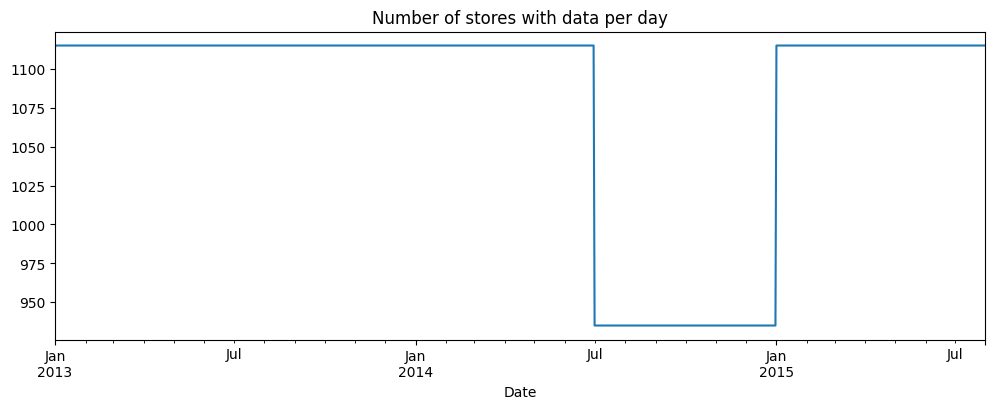

In [4]:
print(train['Open'].value_counts())
print('\nClosed but Sales > 0:', ((train['Open'] == 0) & (train['Sales'] > 0)).sum())
print('Open but Sales = 0:', ((train['Open'] == 1) & (train['Sales'] == 0)).sum())

stores_per_day = train.groupby('Date')['Store'].nunique()
stores_per_day.plot(figsize=(12, 4), title='Number of stores with data per day')

In [5]:
# Are Promo2 columns missing only for stores without Promo2?
no_promo2 = store['Promo2'] == 0
print('Stores without Promo2:', no_promo2.sum())
print('Missing only for those stores:',
      store.loc[no_promo2, 'PromoInterval'].isna().all() and
      store.loc[~no_promo2, 'PromoInterval'].notna().all())

# Which stores are missing in the second half of 2014?
all_stores = set(train['Store'].unique())
stores_on_gap_day = set(train.loc[train['Date'] == '2014-09-01', 'Store'])
missing_stores = sorted(all_stores - stores_on_gap_day)
print('Stores missing in H2 2014:', len(missing_stores))

Stores without Promo2: 544
Missing only for those stores: True
Stores missing in H2 2014: 180


In [6]:
# Keep only open days with positive sales
df = train[(train['Open'] == 1) & (train['Sales'] > 0)].copy()
print('Rows before:', len(train), '| after:', len(df))

# Merge store information
df = df.merge(store, on='Store', how='left')
print('Shape after merge:', df.shape)
df.head()

Rows before: 1017209 | after: 844338
Shape after merge: (844338, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## Data quality findings and decisions

- `train` has no missing values. `Date` was converted to datetime.
- 172,817 rows are closed days (`Open = 0`, Sales = 0) → removed.
- 54 rows are open days with zero sales (likely recording errors) → removed.
- About 180 stores have no data from July to December 2014. → For time trends,
  we use average sales per store instead of total sales.
- Missing `Promo2` dates belong to stores without Promo2 (structural, not real missing values).
- Missing competition information will be handled in the modelling step.

In [7]:
# 'Open' is now always 1, so it carries no information
df = df.drop(columns='Open')

df.to_parquet(DATA_DIR + 'train_clean.parquet', index=False)
print('Saved:', df.shape)

Saved: (844338, 17)
